## Step 1- Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings    
warnings.filterwarnings('ignore')

## Step 2-Load the Dataset

In [3]:
data = pd.read_csv("Bankruptcy_prevention_Dataset.csv", sep=";")

## Step 3-See the first Rows

In [4]:
data.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


head() is used to inspect the first few records and verify that the dataset was loaded correctly and to understand the initial structure of the data.

## Step 4- See the last rows

In [5]:
data.tail()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy
249,1.0,0.0,0.5,0.5,1.0,1.0,non-bankruptcy


Mostly to verify that the complete dataset has loaded properly.

## Step 5-Check Dataset Size

In [6]:
data.shape

(250, 7)

## Step 6- See all columns Names

In [7]:
data.columns

Index(['industrial_risk', ' management_risk', ' financial_flexibility',
       ' credibility', ' competitiveness', ' operating_risk', ' class'],
      dtype='str')

## Step 7-Understand the Dataset structure

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   industrial_risk         250 non-null    float64
 1    management_risk        250 non-null    float64
 2    financial_flexibility  250 non-null    float64
 3    credibility            250 non-null    float64
 4    competitiveness        250 non-null    float64
 5    operating_risk         250 non-null    float64
 6    class                  250 non-null    str    
dtypes: float64(6), str(1)
memory usage: 13.8 KB


## Step 8- Statistical Summary

In [9]:
data.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Step 9-Check data types

In [10]:
data.dtypes

industrial_risk           float64
 management_risk          float64
 financial_flexibility    float64
 credibility              float64
 competitiveness          float64
 operating_risk           float64
 class                        str
dtype: object

## Step 10 -Check for missing values


In [11]:
data.isnull().sum()

industrial_risk           0
 management_risk          0
 financial_flexibility    0
 credibility              0
 competitiveness          0
 operating_risk           0
 class                    0
dtype: int64

## Step 11-Check Duplicate Rows

In [12]:
data.duplicated().sum()

np.int64(147)

Uploaded dataset previously showed 147 duplicate rows.

## Step 12- Separate Numercial Columns


In [13]:
num_cols=data.select_dtypes(include=np.number).columns
num_cols

Index(['industrial_risk', ' management_risk', ' financial_flexibility',
       ' credibility', ' competitiveness', ' operating_risk'],
      dtype='str')

## Step 13- Separate Categorical Columns

In [14]:
cat_cols=data.select_dtypes(include='object').columns
cat_cols

Index([' class'], dtype='str')

this is useful because numerical and categorical variables require different types of analysis.

## Step 14- Count Categories

In [15]:
for col in cat_cols:
    print("\n ",col)
    print(data[col].value_counts())


   class
 class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64


## Step 15- Check unique values

In [16]:
print("\n Unique values in each column:")
for col in data.columns:
    print(col, ":", data[col].nunique())


 Unique values in each column:
industrial_risk : 3
 management_risk : 3
 financial_flexibility : 3
 credibility : 3
 competitiveness : 3
 operating_risk : 3
 class : 2


## Step 16- Histograms

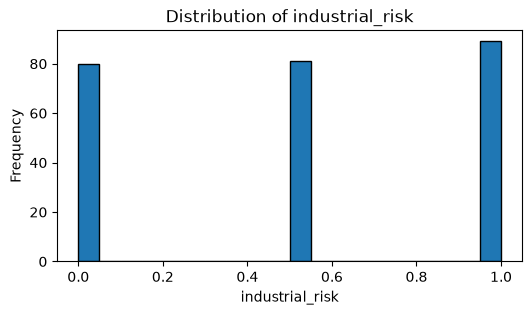

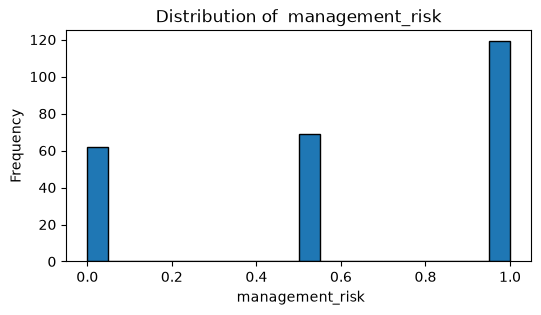

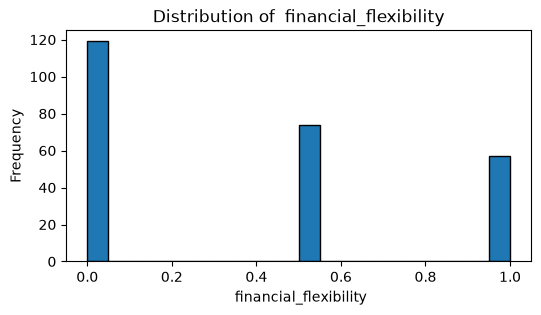

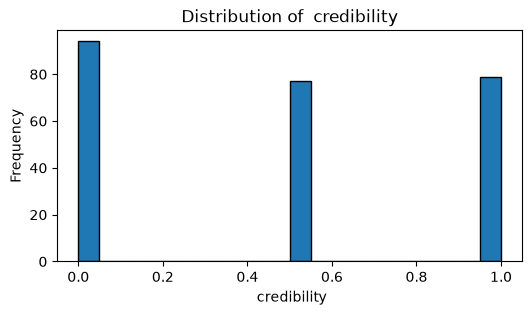

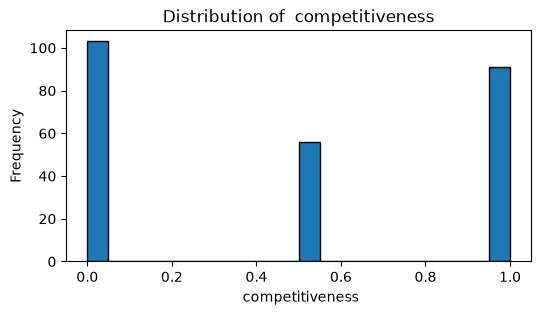

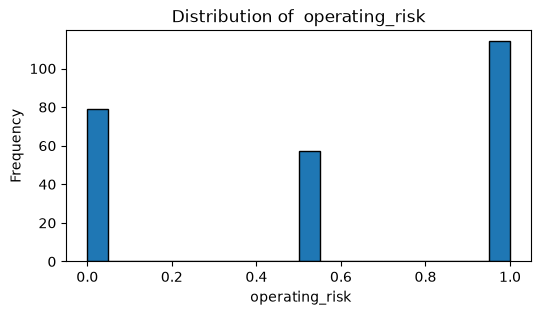

In [17]:
for col in num_cols:
    plt.figure(figsize=(6,3))
    plt.hist(data[col],bins=20,edgecolor='black')
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

Histograms shows how values are distributed.

## Step 17-Boxplots

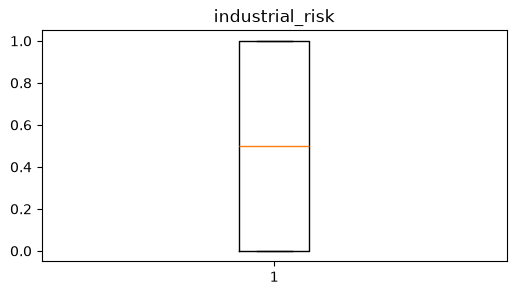

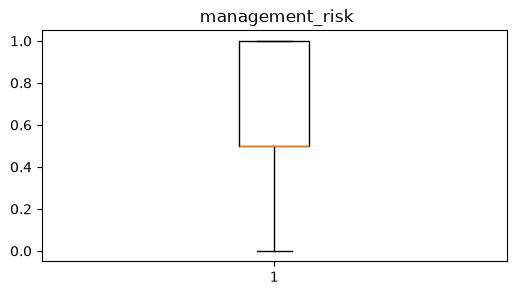

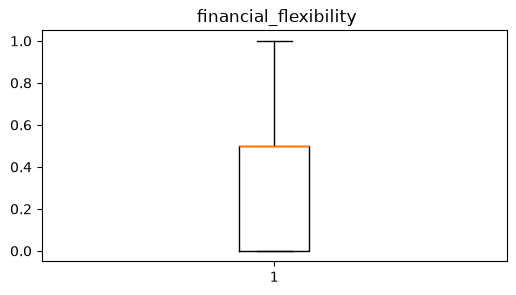

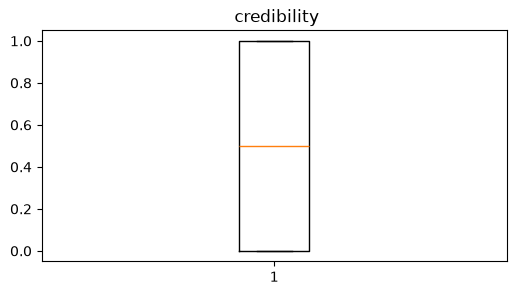

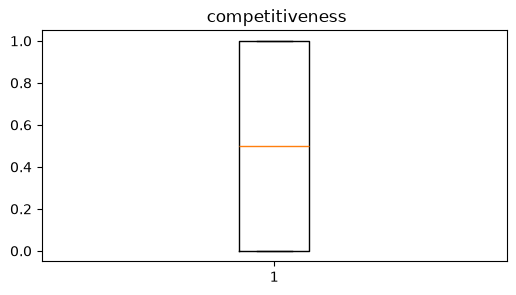

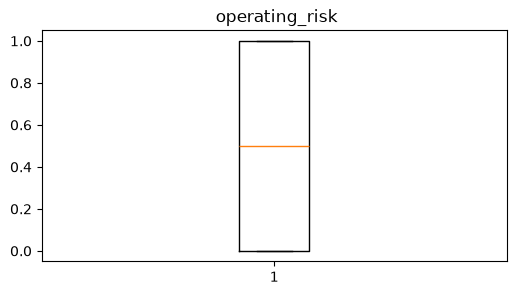

In [18]:
for col in num_cols:
    plt.figure(figsize=(6,3))
    plt.boxplot(data[col])
    plt.title(col)
    plt.show()

Boxplots help identify:median, spread,possible outliers

## Step 18-Categorical Visualization

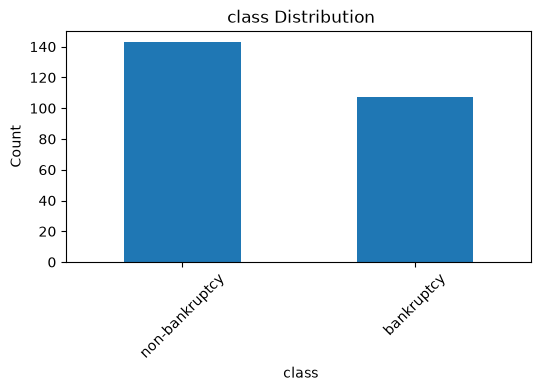

In [19]:
for col in cat_cols:
    plt.figure(figsize=(6,3))
    data[col].value_counts().plot(kind='bar')
    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

## Step 19- Correlation Matrix

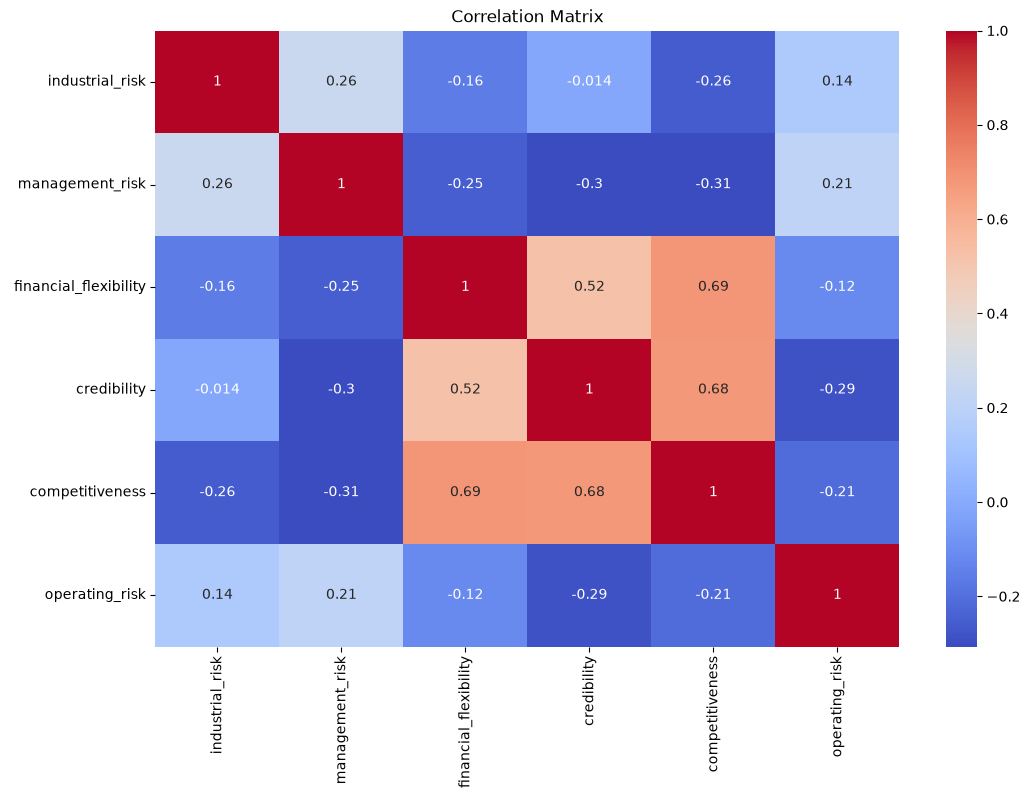

In [20]:
plt.figure(figsize=(12,8))
sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)
plt.title("Correlation Matrix")
plt.show()

## Step 20- Basic Statistical Measures

In [21]:
data[num_cols].mean()

industrial_risk           0.518
 management_risk          0.614
 financial_flexibility    0.376
 credibility              0.470
 competitiveness          0.476
 operating_risk           0.570
dtype: float64

In [22]:
data[num_cols].median()

industrial_risk           0.5
 management_risk          0.5
 financial_flexibility    0.5
 credibility              0.5
 competitiveness          0.5
 operating_risk           0.5
dtype: float64

In [23]:
data[num_cols].std()

industrial_risk           0.411526
 management_risk          0.410705
 financial_flexibility    0.401583
 credibility              0.415682
 competitiveness          0.440682
 operating_risk           0.434575
dtype: float64

## Step 21: Visualize average scores by class

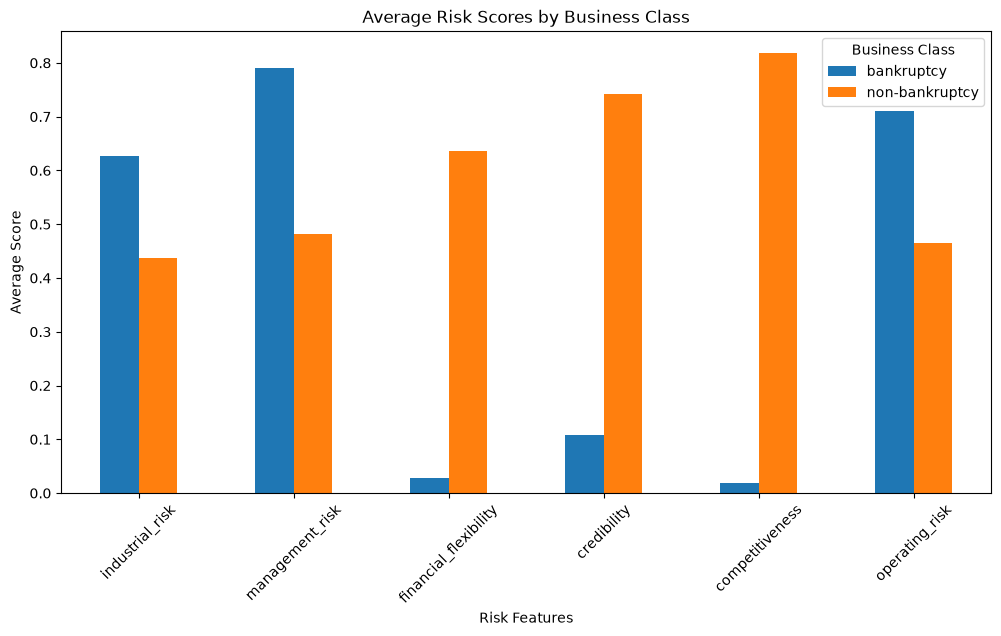

In [24]:
data.columns = (
    data.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)
class_col = next(
    (col for col in data.columns if col == "class"),
    None
)
if class_col is None:
    raise ValueError(
        f"'class' column not found. Available columns: {data.columns.tolist()}"
    )
features = data.select_dtypes(include="number").columns.tolist()
if class_col in features:
    features.remove(class_col)
if not features:
    raise ValueError("No numeric risk features found in the dataset.")
class_means = data.groupby(class_col)[features].mean()
class_means.T.plot(kind="bar", figsize=(12, 6))
plt.title("Average Risk Scores by Business Class")
plt.xlabel("Risk Features")
plt.ylabel("Average Score")
plt.xticks(rotation=45)
plt.legend(title="Business Class")

In [25]:
print('EDA completed successfully!')

EDA completed successfully!


# week 2

## Step -1 Data Cleaning

In [27]:
import pandas as pd
import numpy as np

In [28]:
data_clean = data.copy()

In [29]:
data_clean.columns = (
    data_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

In [30]:
print("Cleaned Column Names:")
print(data_clean.columns)

Cleaned Column Names:
Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk', 'class'],
      dtype='str')


In [31]:
print("\nMissing Values Before Cleaning:")
print(data_clean.isnull().sum())



Missing Values Before Cleaning:
industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64


### duplicate records

In [34]:
print("\nDuplicate Records:")
print(data_clean.duplicated().sum())


Duplicate Records:
147


In [35]:
print("\nMissing Values After Cleaning:")
print(data_clean.isnull().sum())


Missing Values After Cleaning:
industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64


In [36]:
print("\nCleaned Dataset:")
display(data_clean.head())


Cleaned Dataset:


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [37]:
print("\nFinal Dataset Shape:")
print(data_clean.shape)


Final Dataset Shape:
(250, 7)


In [119]:
# REMOVE DUPLICATE ROWS

# 1. Create a copy of the original dataset
data_clean = data.copy()

# 2. Check duplicate records before removal
print("Duplicates before removal:", data_clean.duplicated().sum())

# 3. Remove duplicate records
data_clean = data_clean.drop_duplicates()

# 4. Reset row index
data_clean = data_clean.reset_index(drop=True)

# 5. Check duplicates after removal
print("Duplicates after removal:", data_clean.duplicated().sum())

# 6. Display cleaned dataset shape
print("Final dataset shape:", data_clean.shape)

# 7. Display first five rows
display(data_clean.head())


Duplicates before removal: 147
Duplicates after removal: 0
Final dataset shape: (103, 7)


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


## Step 2 -data pre processing

In [129]:
X = data_clean.drop('class', axis=1)

In [130]:
y = data_clean['class']

In [131]:
y = y.astype(str).str.strip().str.lower()

In [132]:
y = y.map({
    'bankruptcy': 1,
    'non-bankruptcy': 0
})

In [133]:
if y.isnull().any():
    raise ValueError("Check the class column: unexpected values found.")


In [134]:
print("Input Features (X):")
display(X.head())

Input Features (X):


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
0,0.5,1.0,0.0,0.0,0.0,0.5
1,0.0,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,1.0
3,0.5,0.0,0.0,0.5,0.0,1.0
4,1.0,1.0,0.0,0.0,0.0,1.0


In [135]:
print("Target Variable (y):")
display(y.head())

Target Variable (y):


0    1
1    1
2    1
3    1
4    1
Name: class, dtype: int64

In [138]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (103, 6)
Shape of y: (103,)


In [137]:
print("\nTarget Class Distribution:")
print(y.value_counts())


Target Class Distribution:
class
0    78
1    25
Name: count, dtype: int64


## Step 3 -Feature selection

In [139]:
import matplotlib.pyplot as plt
import seaborn as sns

In [140]:
feature_correlation = X.corrwith(y)

In [141]:
feature_correlation = feature_correlation.reindex(
    feature_correlation.abs().sort_values(ascending=False).index
)

print("Feature Correlation with Bankruptcy Class:")
print(feature_correlation)


Feature Correlation with Bankruptcy Class:
competitiveness         -0.859809
financial_flexibility   -0.624573
credibility             -0.606350
industrial_risk          0.217132
management_risk          0.188887
operating_risk           0.136393
dtype: float64


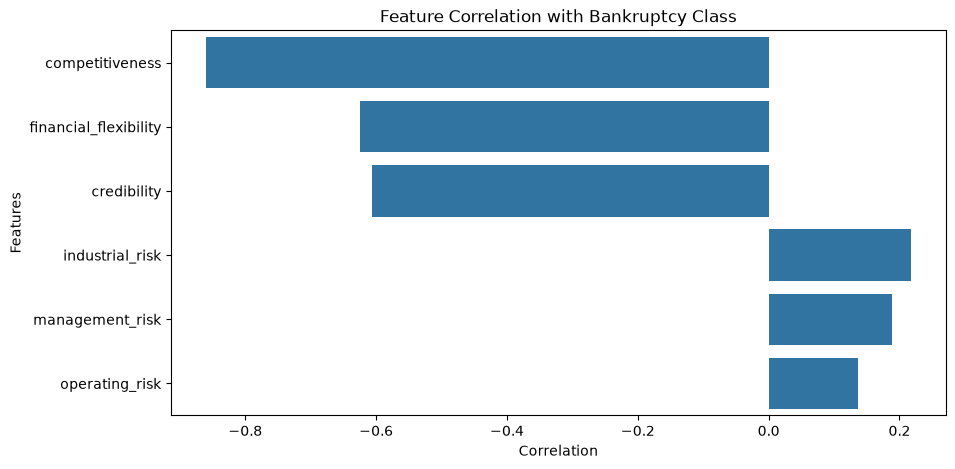

In [142]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=feature_correlation.values,
    y=feature_correlation.index
)

plt.title("Feature Correlation with Bankruptcy Class")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.show()

In [99]:
selected_features = X.columns.tolist()

print("\nSelected Features:")
print(selected_features)


Selected Features:
['industrial_risk', 'management_risk', 'financial_flexibility', 'credibility', 'competitiveness', 'operating_risk']


In [143]:
X_selected = X[selected_features]

print("\nSelected Feature Dataset:")
display(X_selected.head())

print("Shape of selected features:", X_selected.shape)


Selected Feature Dataset:


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
0,0.5,1.0,0.0,0.0,0.0,0.5
1,0.0,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,1.0
3,0.5,0.0,0.0,0.5,0.0,1.0
4,1.0,1.0,0.0,0.0,0.0,1.0


Shape of selected features: (103, 6)


## Step 4- Train test split

In [101]:
from sklearn.model_selection import train_test_split

In [144]:
X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [145]:
print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

Training Features: (82, 6)
Training Target: (82,)


In [146]:
print("\nTesting Features:", X_test.shape)
print("Testing Target:", y_test.shape)


Testing Features: (21, 6)
Testing Target: (21,)


In [147]:
print("\nTraining Class Distribution:")
print(y_train.value_counts())


Training Class Distribution:
class
0    62
1    20
Name: count, dtype: int64


In [148]:
print("\nTesting Class Distribution:")
print(y_test.value_counts())


Testing Class Distribution:
class
0    16
1     5
Name: count, dtype: int64


## Step 5 -Model Building

In [149]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [150]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC()
}

#Creating machine learning models

In [151]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "model trained successfully")

Logistic Regression model trained successfully
Decision Tree model trained successfully
Random Forest model trained successfully
SVM model trained successfully


#Generating predictions

In [110]:
model_predictions = {}

for name, model in models.items():
    model_predictions[name] = model.predict(X_test)

print("\nAll models trained and predictions generated!")


All models trained and predictions generated!


## Step 6- Model evaluation

In [152]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [153]:
results = []

In [162]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# Create comparison table
results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(3))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.905,1.0,0.6,0.750
1,Decision Tree,0.952,1.0,0.8,0.889
2,Random Forest,0.952,1.0,0.8,0.889
3,SVM,0.905,1.0,0.6,0.750


In [163]:
for name, model in models.items():

    print("\nClassification Report:", name)

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Non-bankruptcy", "Bankruptcy"],
        zero_division=0
    ))


Classification Report: Logistic Regression
                precision    recall  f1-score   support

Non-bankruptcy       0.89      1.00      0.94        16
    Bankruptcy       1.00      0.60      0.75         5

      accuracy                           0.90        21
     macro avg       0.94      0.80      0.85        21
  weighted avg       0.92      0.90      0.90        21


Classification Report: Decision Tree
                precision    recall  f1-score   support

Non-bankruptcy       0.94      1.00      0.97        16
    Bankruptcy       1.00      0.80      0.89         5

      accuracy                           0.95        21
     macro avg       0.97      0.90      0.93        21
  weighted avg       0.96      0.95      0.95        21


Classification Report: Random Forest
                precision    recall  f1-score   support

Non-bankruptcy       0.94      1.00      0.97        16
    Bankruptcy       1.00      0.80      0.89         5

      accuracy                  

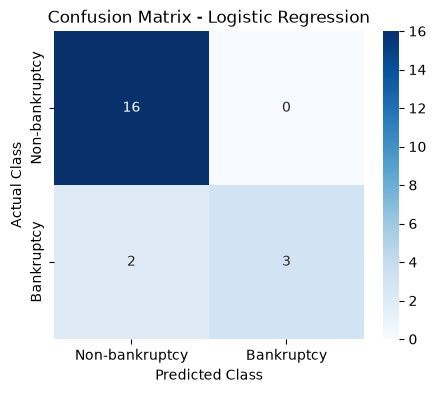

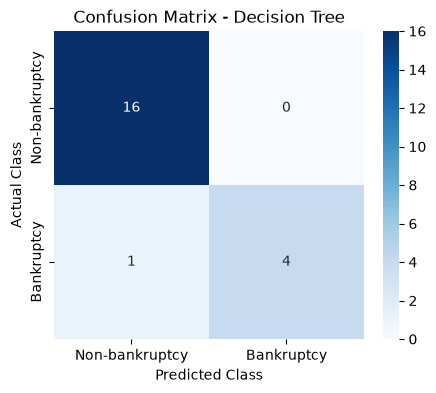

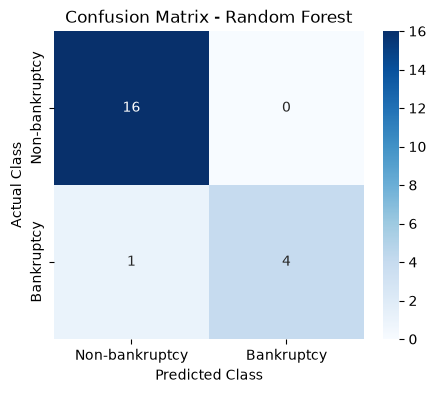

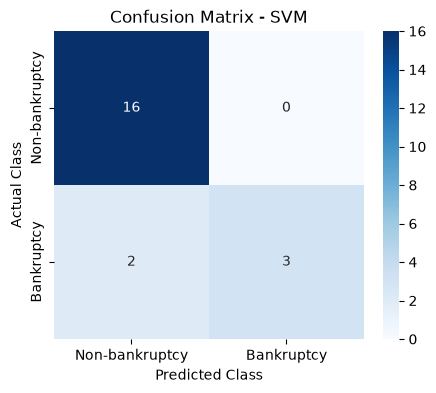

In [164]:
for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-bankruptcy", "Bankruptcy"],
        yticklabels=["Non-bankruptcy", "Bankruptcy"]
    )
    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.show()


### Final Prediction

In [165]:

# STEP 7: FINAL PREDICTION

# 1. Select a model
best_model = models["Random Forest"]

# 2. Enter new business risk details
new_business = pd.DataFrame([{
    "industrial_risk": 0.5,
    "management_risk": 0.5,
    "financial_flexibility": 0.5,
    "credibility": 0.5,
    "competitiveness": 0.5,
    "operating_risk": 0.5
}])

# 3. Predict the business class
prediction = best_model.predict(new_business)

# 4. Display the result
if prediction[0] == 1:
    print("Prediction: Bankruptcy")
else:
    print("Prediction: Non-bankruptcy")


Prediction: Non-bankruptcy


- Selected model: Random Forest
- Accuracy: 95.24%
- Correct predictions: 20 out of 21
- Bankruptcy cases identified: 4 out of 5
- Missed bankruptcy cases: 1
Final prediction: Your Random Forest model can classify a business as either Bankruptcy or Non-bankruptcy based on its six risk factors.

To predict a specific new business, you need to enter its six risk-factor values. The screenshots do not show an individual business prediction.

In [166]:

# STEP 8A: SAVE THE TRAINED MODEL

import joblib

# Select Random Forest model
best_model = models["Random Forest"]

# Save model and feature names together
model_data = {
    "model": best_model,
    "features": X_selected.columns.tolist()
}

joblib.dump(model_data, "bankruptcy_model.pkl")

print("Model saved successfully!")
print("Saved file: bankruptcy_model.pkl")


Model saved successfully!
Saved file: bankruptcy_model.pkl


In [172]:

import streamlit as st
import pandas as pd
import joblib

# Load saved model
model_data = joblib.load("bankruptcy_model.pkl")

model = model_data["model"]
features = model_data["features"]

# Page configuration
st.set_page_config(
    page_title="Bankruptcy Prevention System",
    page_icon="📊",
    layout="centered"
)

# Application title
st.title("Bankruptcy Prevention System")
st.write(
    "Enter the business risk factors to predict "
    "the bankruptcy classification."
)

st.divider()

# Input fields
st.subheader("Business Risk Factors")

risk_options = [0, 0.5, 1]

risk_labels = {
    0: "0 - Low",
    0.5: "0.5 - Medium",
    1: "1 - High"
}

input_values = {}

for feature in features:
    input_values[feature] = st.selectbox(
        feature.replace("_", " ").title(),
        options=risk_options,
        format_func=lambda x: risk_labels[x]
    )

st.divider()

# Prediction button
if st.button("Predict Bankruptcy", type="primary"):

    input_data = pd.DataFrame(
        [input_values],
        columns=features
    )

    prediction = model.predict(input_data)

    st.subheader("Prediction Result")

    if prediction[0] == 1:
        st.error("Prediction: Bankruptcy")
        st.warning(
            "The model has classified this business "
            "as Bankruptcy."
        )
    else:
        st.success("Prediction: Non-bankruptcy")
        st.info(
            "The model has classified this business "
            "as Non-bankruptcy."
        )

st.caption(
    "This is an educational machine learning project. "
    "Predictions are not financial advice."
)

2026-11-04 16:04:13.864 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-04 16:04:13.880 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-04 16:04:13.881 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-04 16:04:13.886 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-04 16:04:13.890 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-04 16:04:13.890 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-04 16:04:13.890 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-04 16:04:13.891 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

In [168]:
pip install streamlit pandas scikit-learn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 1.7 MB/s eta 0:00:000:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 931.1 kB/s eta 0:00:00MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 688.7 kB/s eta 0:00:00m eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 694.4 kB/s eta 0:00:000:00:01m eta 0:00:01
Note: you may need to restart the kernel to use updated packages.
